In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [19]:
df = pd.read_csv("samplesuperstore.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [20]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 10194
Columns: 21


In [21]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (10194, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types:
Row ID              int64
Order ID           object
Order Date         object
Ship Date          object
Ship Mode          object
Customer ID        object
Customer Name      object
Segment            object
Country/Region     object
City               object
State/Province     object
Postal Code        object
Region             object
Product ID         object
Category           object
Sub-Category       object
Product Name       object
Sales             float64
Quantity            int64
Discount          float64
Profit            float64
dtype: object


In [22]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

Duplicate rows: 0


In [23]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [24]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,228.225854,3.791838,0.155385,28.673417
std,619.906839,2.228317,0.206249,232.465115
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.220000,2.000000,0.000000,1.760800
50%,53.910000,3.000000,0.200000,8.690000
75%,209.500000,5.000000,0.200000,29.297925
max,22638.480000,14.000000,0.800000,8399.976000


In [25]:
category_summary = df.groupby("Category")[["Sales", "Profit"]].sum()

category_summary

,Sales,Profit
Category,,
Furniture,754747.7613,19729.9956
Office Supplies,731893.3140,126023.4434
Technology,839893.2790,146543.3756


In [26]:
region_summary = df.groupby("Region")[["Sales", "Profit"]].sum()

region_summary

,Sales,Profit
Region,,
Central,503170.6728,39865.3070
East,691828.1680,94883.2603
South,391721.9050,46749.4303
West,739813.6085,110798.8170


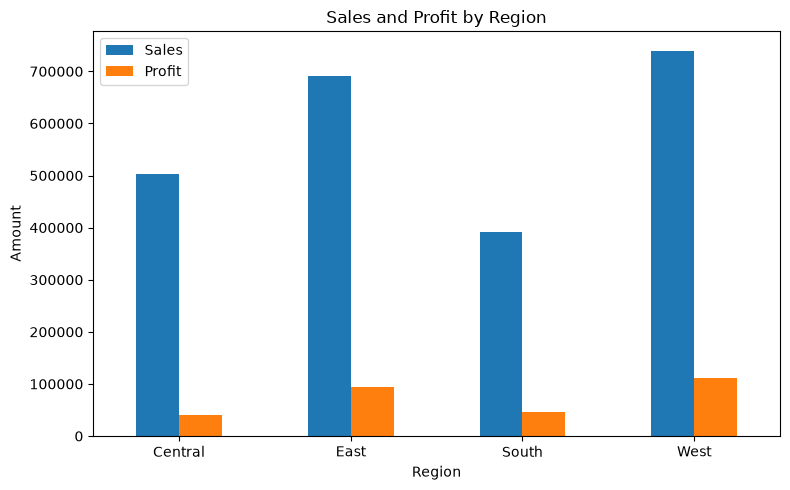

In [27]:
region_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales and Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

monthly_sales.head()

Order Date
2023-01    14518.055
2023-02     4519.892
2023-03    56933.909
2023-04    28295.345
2023-05    26319.767
Freq: M, Name: Sales, dtype: float64

In [29]:
subcategory_summary = (
    df.groupby("Sub-Category")[["Sales", "Profit"]]
    .sum()
    .sort_values("Profit", ascending=False)
)

subcategory_summary

,Sales,Profit
Sub-Category,,
Copiers,150745.2900,56093.9365
Phones,331842.6400,45050.8265
Accessories,167380.3180,41936.6357
Paper,79540.5380,34511.5070
Binders,207354.8810,31426.1003
Chairs,335768.2490,27223.5323
Storage,224644.5540,21285.1115
Appliances,108213.1850,18329.4844
Furnishings,95598.1260,13891.7430


In [30]:
discount_profit_corr = df["Discount"].corr(df["Profit"])

discount_profit_corr

-0.21888187168876128

In [31]:
discount_summary = (
    df.groupby("Discount")["Profit"]
    .agg(["count", "mean", "sum"])
    .round(2)
)

discount_summary

,count,mean,sum
Discount,,,
0.00,4925,66.34,326718.59
0.10,96,94.79,9099.97
0.15,52,27.29,1418.99
0.20,3706,24.58,91079.95
0.30,230,-45.71,-10513.45
0.32,27,-88.56,-2391.14
0.40,207,-111.53,-23086.37
0.45,11,-226.65,-2493.11
0.50,66,-310.70,-20506.43


In [32]:
no_discount_profit = df[df["Discount"] == 0]["Profit"]
discounted_profit = df[df["Discount"] > 0]["Profit"]

t_stat, p_value = stats.ttest_ind(
    no_discount_profit,
    discounted_profit,
    equal_var=False
)

print("No-discount mean profit:", no_discount_profit.mean())
print("Discounted mean profit:", discounted_profit.mean())
print("t-statistic:", t_stat)
print("p-value:", p_value)

No-discount mean profit: 66.33879943147207
Discounted mean profit: -6.53288529132663
t-statistic: 15.89407873219623
p-value: 3.727020207313894e-56


### Statistical Analysis: Discount and Profit

To investigate whether discounted orders have different average profit
from orders without discounts, a Welch two-sample t-test was performed.

**Hypotheses:**

- H₀: The mean profit is the same for discounted and non-discounted orders.
- H₁: The mean profit differs between discounted and non-discounted orders.

**Results:**

- No-discount mean profit: 66.34
- Discounted mean profit: -6.53
- t-statistic: 15.89
- p-value: 3.73 × 10⁻⁵⁶
- Significance level: 0.05

**Interpretation:**

The p-value is substantially below 0.05, so we reject H₀.
There is strong statistical evidence that average profit differs
between discounted and non-discounted orders in this dataset.

The discounted group has a lower average profit, suggesting that
discounting is associated with reduced profitability. However, this
analysis shows an association rather than proving that discounts
alone cause lower profit, because other factors such as product,
region, customer segment, and order characteristics may also affect
profit.

In [33]:
segment_summary = (
    df.groupby("Segment")[["Sales", "Profit"]]
    .sum()
    .sort_values("Profit", ascending=False)
    .round(2)
)

segment_summary

,Sales,Profit
Segment,,
Consumer,1170659.79,136371.45
Corporate,715806.13,94249.64
Home Office,440068.43,61675.73


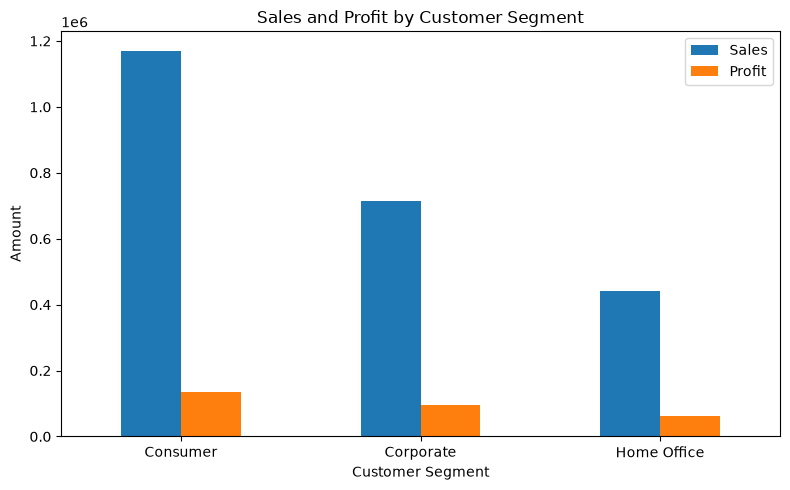

In [34]:
segment_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales and Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Business Question

Which products, regions, customer segments, and discount levels are driving
sales and profitability, and what actions can the business take to improve
profitability?

## Key Analysis Areas

1. Sales and profit by category and sub-category
2. Regional sales and profitability
3. Monthly sales trends
4. Customer segment performance
5. Relationship between discount and profit
6. Statistical comparison of discounted vs non-discounted orders